# Проект "Рынок общественного питания"

## 1. Описание проекта

### 1.1 Цели и задачи

**Цель:** Провести исследовательский анализ рынка общественного питания в Москве для выявления закономерностей в данных и взаимосвязей между ними, а также для составления рекомендаций для входа на данный рынок.

**Задачи:**

1. Загрузить данные и познакомиться с их содержимым.
2. Провести предобработку данных.
3. Провести исследовательский анализ данных опираясь на поставленные вопросы.
4. Сформулировать выводы и рекомендации по проведенному анализу.

### 1.2 Вопросы для исследования

1. Какие категории заведений представлены в данных? Сколько заведений каждой категории?
2. Как заведения распределяются по административным районам Москвы? Есть ли разница в распределении по категориям в Центральном районе?
3. Каких заведений больше — сетевых или несетевых? Какие категории заведений чаще являются сетевыми?
4. Встречаются ли в данных о количестве посадочных мест аномальные значения или выбросы? Если да, то с чем они могут быть связаны? Какое типичное количество мест для разных категорий заведений?
5. Какие типичные типичные значения рейтинга в целом и у различных категорий заведений?
6. С какими данными рейтинги заведений показывают самую сильную корреляцию?
7. Какие сетевые заведения имеют больше всего точек? К какой категории заведений они относятся?
8. Как удаленность от центра влияет на цены в заведениях?

### 1.3 Описание данных

Для анализа использовались данные с заведениями общественного питания Москвы, полученные на основе данных сервисов Яндекс Карты и Яндекс Бизнес за лето 2022 года. Данные состоят из двух датасетов:

- `rest_info.csv` - содержит информацию о заведениях общественного питания;
- `rest_price.csv` - содержит информацию о среднем чеке в заведениях общественного питания.

Описание датасета `rest_info.csv`:

- `name` — название заведения;
- `address` — адрес заведения;
- `district` — административный район, в котором находится заведение, например Центральный административный округ;
- `category` — категория заведения, например «кафе», «пиццерия» или «кофейня»;
- `hours` — информация о днях и часах работы;
- `rating` — рейтинг заведения по оценкам пользователей в Яндекс Картах (высшая оценка — 5.0);
- `chain` — число, выраженное 0 или 1, которое показывает, является ли заведение сетевым (для маленьких сетей могут встречаться ошибки):
  
0 — заведение не является сетевым;

1 — заведение является сетевым.
- `seats` — количество посадочных мест.

Описание датасета `rest_price.csv`:

- `price` — категория цен в заведении, например «средние», «ниже среднего», «выше среднего» и так далее;
- `avg_bill` — хранит среднюю стоимость заказа в виде диапазона;
- `middle_avg_bill` — число с оценкой среднего чека, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Средний счёт»;
- `middle_coffee_cup` — число с оценкой одной чашки капучино, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Цена одной чашки капучино».

### 1.4 План работы

1. Описание проекта
2. Загрузка данных и знакомство с ними
3. Предобработка данных
4. Исследовательский анализ данных
5. Итоговые выводы и рекомендации

## 2. Загрузка данных и знакомство с ними

### 2.1 Загрузка библиотек и датафреймов
Начнём с загрузки библиотек и датасетов `rest_info` и `rest_price`. Будем использовать pandas и библиотеки визуализации данных matplotlib и seaborn, а также phik для построения матрицы корреляции. Данные датасетов сохраним в двух переменных: `rest_df` и `price_df`.

In [1]:
# Устанавливаем библиотеку phik
!pip install phik -U

In [2]:
# Импортируем библиотеки для анализа данных
import pandas as pd
import numpy as np

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns

# Загружаем библиотеку для расчёта коэффициента корреляции phi_k
from phik import phik_matrix

In [3]:
# Выгружаем данные в переменные bank_df и clients_df
rest_df = pd.read_csv('https://code.s3.yandex.net/datasets/rest_info.csv')
price_df = pd.read_csv('https://code.s3.yandex.net/datasets/rest_price.csv')

### 2.2 Обзор общей информации

Познакомимся с данными датасета `rest_info.csv` — выведем первые строки методом `head()`, а информацию о датафрейме методом `info()`:

In [4]:
# Выводим первые строки датафрейма на экран
rest_df.head()

,id,name,category,address,district,hours,rating,chain,seats
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0


In [5]:
# Выводим информацию о датафрейме
rest_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        8406 non-null   object 
 1   name      8406 non-null   object 
 2   category  8406 non-null   object 
 3   address   8406 non-null   object 
 4   district  8406 non-null   object 
 5   hours     7870 non-null   object 
 6   rating    8406 non-null   float64
 7   chain     8406 non-null   int64  
 8   seats     4795 non-null   float64
dtypes: float64(2), int64(1), object(6)
memory usage: 591.2+ KB


Датасет `rest_info.csv` содержит 9 столбцов и 8406 строк, в которых представлена информация о заведениях общественного питания.

После первичного анализа данных можно сделать следующие выводы:
- Названия столбцов имеют подходящий стиль написания
- Значения в столбцах `id`, `name`, `category`, `address`, `district` и `hours` представлены смешанным типом данных. Для `category` и `district` его можно поменять на категориальный тип данных.
- Значения в столбцах `rating` и `seats` представлены типом данных `float64`. Для `seats` тип данных следует поменять на `Int64`.
- Значения в столбце `chain` представлены типом данных `int8`. Здесь можно понизить разрядность до `int8`, так как в этом столбце только два значения - 0 и 1.
- Присутствуют пропуски в столбце `hours`, и почти половина данных отсутствует в столбце `seats`.
- Судя по первому знакомству с данными, значения в столбцах соответствуют своему описанию.

Теперь познакомимся с данными датасета `rest_price.csv`.

In [6]:
# Выводим первые строки датафрейма на экран
price_df.head()

,id,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,045780ada3474c57a2112e505d74b633,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
1,1070b6b59144425896c65889347fcff6,средние,Средний счёт:от 1000 ₽,1000.0,NaN
2,03ac7cd772104f65b58b349dc59f03ee,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
3,a163aada139c4c7f87b0b1c0b466a50f,средние,Средний счёт:400–600 ₽,500.0,NaN
4,8a343546b24e4a499ad96eb7d0797a8a,средние,NaN,NaN,NaN


In [7]:
# Выводим информацию о датафрейме
price_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4058 non-null   object 
 1   price              3315 non-null   object 
 2   avg_bill           3816 non-null   object 
 3   middle_avg_bill    3149 non-null   float64
 4   middle_coffee_cup  535 non-null    float64
dtypes: float64(2), object(3)
memory usage: 158.6+ KB


Датасет `rest_price.csv` содержит 5 столбцов и 4058 строк, в которых представлена информация о среднем чеке в заведениях общественного питания. По аналогии с предыдущим датасетом можно отметить, что:

- Названия столбцов имеют подходящий стиль написания.
- Типы данных соответствуют содержимому. Столбец `price` можно привести к категориальному типу данных.
- Во всех столбцах, кроме `id`, присутствуют пропуски, особенно много их в столбце `middle_coffee_cup`.
- Судя по первому знакомству с данными, значения в столбцах соответствуют своему описанию.

Теперь изучим столбцы отдельно.

### 2.3 Обзор категориальных и бинарных данных

In [8]:
# Выводим уникальные значения category
rest_df['category'].unique()

array(['кафе', 'ресторан', 'кофейня', 'пиццерия', 'бар,паб',
       'быстрое питание', 'булочная', 'столовая'], dtype=object)

Результаты показывают, что всего в этом столбце 8 уникальных значений.

In [9]:
# Выводим уникальные значения district
rest_df['district'].unique()

array(['Северный административный округ',
       'Северо-Восточный административный округ',
       'Северо-Западный административный округ',
       'Западный административный округ',
       'Центральный административный округ',
       'Восточный административный округ',
       'Юго-Восточный административный округ',
       'Южный административный округ',
       'Юго-Западный административный округ'], dtype=object)

Здесь видно, что различных районов 9.

In [10]:
# Выводим уникальные значения chain
rest_df['chain'].unique()

array([0, 1])

У данного столбца только булевые значения.

In [11]:
# Выводим уникальные значения price
price_df['price'].unique()

array(['выше среднего', 'средние', nan, 'высокие', 'низкие'], dtype=object)

В этом столбце также все значения уникальные, однако присутствуют пропуски.

Как итог, категориальные и бинарные данные в порядке, неявных дубликатов в них нет.

### 2.4 Поиск выбросов и аномалий в числовых данных

Изучим числовые данные в столбцах из обеих таблиц на предмет выбросов. Для начала напишем функцию для визуализации, так как она понадобится нам сразу для 4 показателей.

In [12]:
# Создаем функцию для построения диаграммы размаха
def plot_boxplot(data, title="Диаграмма размаха"):
    """
    Строит диаграмму размаха по переданным данным.

    Параметры:
        data (list или array): числовые данные
        title (str): заголовок графика
    """
    plt.figure(figsize=(8, 5))
    plt.boxplot(data, vert=False)
    plt.title(title)
    plt.grid(False)
    plt.tight_layout()
    plt.show()

Начнем с данных в столбце `rating`

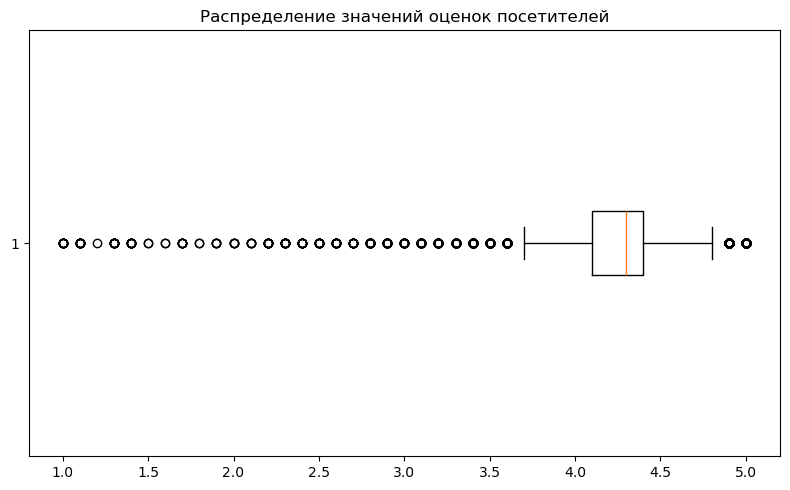

In [13]:
# Построим диаграмму размаха
plot_boxplot(data=rest_df['rating'], title='Распределение значений оценок посетителей')

Можно сделать следующие выводы:

- **Распределение сильно скошено влево.** На графике ящика с усами слева от левого уса видно большое количество отдельных точек (выбросов) в диапазоне 1.0–3.5: это реальные заведения с низкими оценками, которые статистически отличаются от основной массы.
- **Аномальных значений и крупных выбросов среди рейтингов не наблюдается.**

Теперь рассмотрим следующий столбец - `seats`

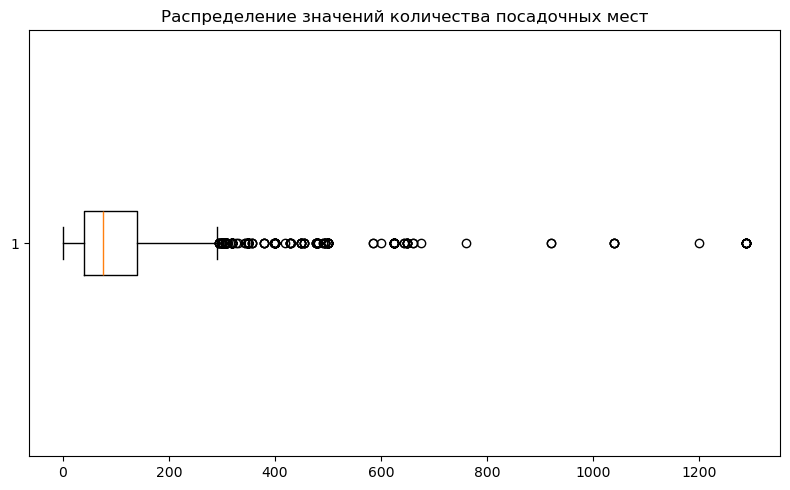

In [14]:
# Построим диаграмму размаха
plot_boxplot(data=rest_df['seats'].dropna(), title='Распределение значений количества посадочных мест')

Можно сделать следующие выводы:

- **Значительная доля экстремальных значений (выбросов).** На boxplot видно много отдельных точек‑выбросов справа — это крупные объекты (банкетные залы, столовые, фуд‑корты) с вместимостью 300–1300 мест. Они встречаются редко, но сильно влияют на общую картину: повышают среднее значение и увеличивают дисперсию (std = 122.8).
- **Минимальное значение равно 0**. Это могут быть как пропущенные данные, так и заведения работающие только на доставку/вынос.
- **Для анализа типичной ситуации на рынке следует сузить диапазон.** Если ограничить анализ диапазоном 1–300 мест (исключив нули и крупные объекты), распределение станет гораздо нагляднее и лучше отразит типичные форматы заведений питания.

Далее исследуем `middle_avg_bill`.

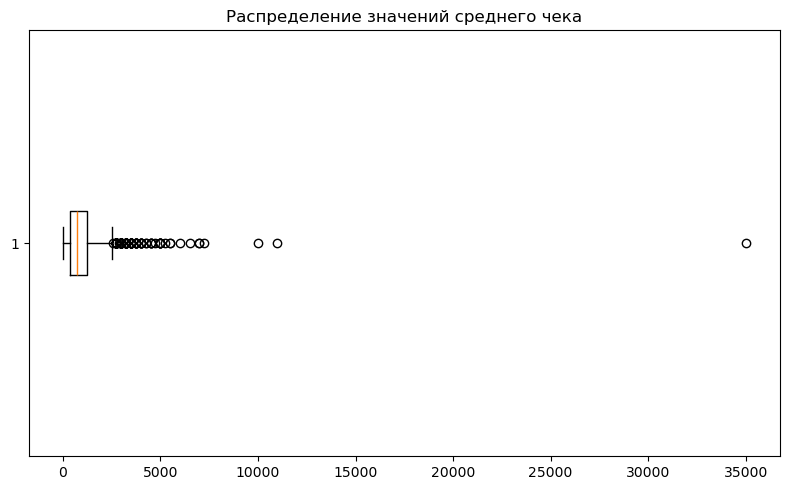

In [15]:
# Построим диаграмму размаха
plot_boxplot(data=price_df['middle_avg_bill'].dropna(), title='Распределение значений среднего чека')

Можно сделать следующие выводы:

- **Распределение резко скошено вправо, но основная масса заведений — в бюджетном сегменте.**
На boxplot виден компактный ящик в левой части, а справа от него большое кол-во выбросов.
- **Сильное искажение типичных значений выбросами.**
 Для анализа массового рынка следует исключить значения выше 5000 ₽, которые либо являются аномальными, либо представляют заведения премиального уровня.
- **Нулевые значения — это, скорее всего, пропуски или технические ошибка.**
Минимум равен 0 ₽. В контексте среднего чека это почти всегда означает отсутствие данных. Для дальнейшего анализа такие строки лучше исключить.

Остался последний столбец - `middle_coffee_cup`.

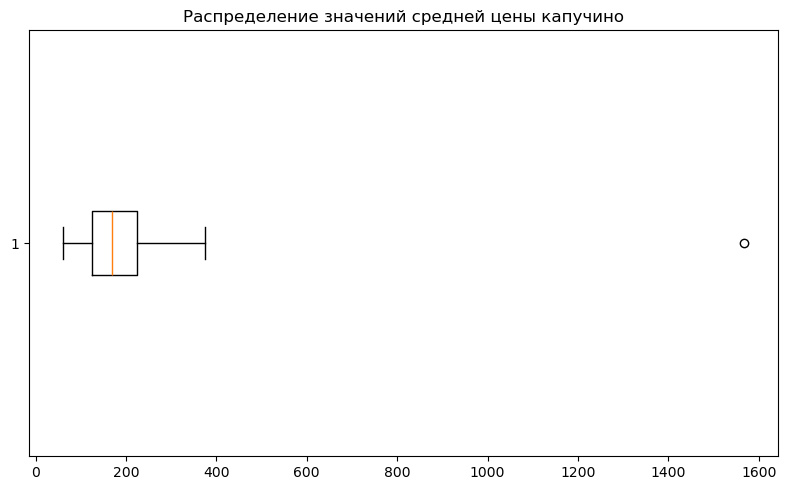

In [16]:
# Построим диаграмму размаха без выбросов
plot_boxplot(data=price_df['middle_coffee_cup'].dropna(), title='Распределение значений средней цены капучино')

Можно сделать следующие выводы:

- **Однородность базового сегмента рынка.**
Диаграмма размаха (boxplot) показывает, что основная масса заведений держит цену капучино в диапазоне примерно 130–230 ₽. Это подтверждает, что рынок в массовом сегменте достаточно консолидирован: заведения не стремятся сильно завышать или занижать цену на этот базовый напиток.
- **Широкий разброс в «хвостах» распределения.**
Усы диаграммы доходят примерно до 60 ₽ (минимум) и 370 ₽ (максимум). У кофеен есть как дешевый, так и дорогой сегменты, однако они не слишком большие.
- **Присутствует 1 выброс в правой части.** Его следует убрать.

Первичное знакомство показывает, что данные соответствуют описанию и выглядят корректными, однако требуется поработать над пропусками и типами данных.

Для удобства в дальнейшей части проекта объеденим оба датафрейма в один. В таблице с ценами строк более чем в 2 раза меньше, но для анализа возьмем полные данные.

In [17]:
# Объединяем датафреймы rest_df и price_df в датафрейм df
df = pd.merge(rest_df, price_df, on='id', how='outer')

In [18]:
# Проверим размерность получившегося датасета
df.shape

(8406, 13)

Теперь в датасете 13 столбцов

In [19]:
# Зафиксируем изначальное кол-во строк
initial_rows = df.shape[0]

## 3. Предобработка данных

### 3.1 Оптимизация типов данных
Для начала приведем часть столбцов к категориальному типу данных

In [20]:
# Меняем тип данных в столбцах category, district, price на категориальный
list_ch = ['category', 'district', 'price']
for column in list_ch:
    df[column] = df[column].astype('category')

Теперь поменяем тип данных столбца `seats` на `Int16`

In [21]:
# Меняем тип данных в столбце seats на Int16
df['seats'] = df['seats'].astype('Int16')

Осталось понизить разрядность для столбца `chain`

In [22]:
# Меняем тип данных в столбце chain на int8
df['chain'] = df['chain'].astype('int8')

In [23]:
# Проверим рузультат
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   id                 8406 non-null   object  
 1   name               8406 non-null   object  
 2   category           8406 non-null   category
 3   address            8406 non-null   object  
 4   district           8406 non-null   category
 5   hours              7870 non-null   object  
 6   rating             8406 non-null   float64 
 7   chain              8406 non-null   int8    
 8   seats              4795 non-null   Int16   
 9   price              3315 non-null   category
 10  avg_bill           3816 non-null   object  
 11  middle_avg_bill    3149 non-null   float64 
 12  middle_coffee_cup  535 non-null    float64 
dtypes: Int16(1), category(3), float64(3), int8(1), object(5)
memory usage: 583.9+ KB


Теперь все типы данных установлены корректно. Перейдем к следующему этапу.

### 3.2 Поиск и обработка пропусков

Как мы видим пропуски содержаться в 6 столбцах датафрейма, подсчитаем их долю.

In [24]:
# Подсчитываем долю строк с пропусками
df.isna().sum() / df.shape[0]

id                   0.000000
name                 0.000000
category             0.000000
address              0.000000
district             0.000000
hours                0.063764
rating               0.000000
chain                0.000000
seats                0.429574
price                0.605639
avg_bill             0.546039
middle_avg_bill      0.625387
middle_coffee_cup    0.936355
dtype: float64

В столбцах `seats`, `price`, `avg_bill`, `middle_avg_bill` отсутствует около 40-60% данныых. А в столбце `middle_coffee_cup` более 93%. В столбце `hours` примерно 6%.

Пропуски в этих столбцах могут быть вызваны:

- В столбцах `middle_avg_bill` и `middle_coffee_cup` значения рассчитываются только при наличии строго определенного текста в другом столбце, и, скорее всего, связаны с конкретными типами заведений. Например, `middle_avg_bill` связано с кафе и ресторанами, а `middle_coffee_cup` с кофейнями. Этот тип пропусков можно отнести к типу MCAR. Следовательно, наличие такого количества пропусков в этих столбцах это нормальное явление.
- В столбцах `seats` и `hours` содержатся данные о посадочных местах и графике работы: не всегда эти данные публикуются открыто, а в некоторых заведениях может не быть посадочных мест вовсе.
- Для столбцов `price` и `avg_bill` также может не быть данных в открытых источниках, либо их может быть недостаточно.

Для целей исследовательского анализа лучше оставить пропуски как есть. Использование средних значений слишком сильно разбавит данные.

Теперь проверим наличие явных дубликатов.

### 3.3 Поиск и обработка дубликатов

In [25]:
# Проверяем полные дубликаты в датафрейме df
df.duplicated().sum()

np.int64(0)

В датафреймах нет полных дубликатов строк. Проверим неявные дубликаты — значения по `id` заведений должны быть уникальными, то есть каждая строка в данных — уникальное заведение:

In [26]:
# Проверяем неявные дубликаты в датафрейме df по столбцу id
df.duplicated(subset='id').sum()

np.int64(0)

Тут тоже всё хорошо — каждая строка соответствует уникальному заведению, но на всякий случай проверим также столбцы с названиями и адресами заведений.

In [27]:
# Нормализуем значения в столбцах name и address
for column in ['name', 'address']:
    df[column] = df[column].str.lower().str.strip()

In [28]:
# Проверяем неявные дубликаты в датафрейме df по столбцу name
df['name'].value_counts().head(10)

name
кафе                189
шоколадница         120
домино'с пицца       77
додо пицца           74
one price coffee     72
яндекс лавка         69
cofix                65
prime                50
хинкальная           44
шаурма               43
Name: count, dtype: int64

Как мы видим, одинаковые названия имеют либо сетевые заведения, либо заведения с типовым названием, что дубликатами не является.

In [29]:
# Проверяем неявные дубликаты в датафрейме df по столбцу address
df['address'].value_counts().head(10)

address
москва, проспект вернадского, 86в       28
москва, усачёва улица, 26               26
москва, ярцевская улица, 19             20
москва, площадь киевского вокзала, 2    20
москва, лесная улица, 20, стр. 3        16
москва, проспект мира, 211к2            16
москва, пресненская набережная, 2       16
москва, хорошёвское шоссе, 27           16
москва, щёлковское шоссе, вл75          16
москва, каширское шоссе, 61г            16
Name: count, dtype: int64

Здесь тоже ситуация неоднозначна: по одному адресу может быть несколько заведений питания, особенно если это торговый центр.

### 3.4 Очистка данных от выбросов
Очистим от выбросов числовые столбцы, изученные раннее. Начнем со столбца `seats`

In [30]:
# Очистим от выбросов столбец seats
mask = (
    df['seats'].between(1, 300)
    | df['seats'].isna()
)
df = df[mask]

Теперь столбец `middle_avg_bill`

In [31]:
# Заменим в столбце middle_avg_bill нулевые значения на NaN
df.loc[df['middle_avg_bill'] == 0, 'middle_avg_bill'] = np.nan

In [32]:
# Очистим от выбросов столбец middle_avg_bill
mask = (
    df['middle_avg_bill'] <= 5000
) | df['middle_avg_bill'].isna()
df = df[mask]

Наконец, столбец `middle_coffee_cup`

In [33]:
# Очистим от выброса столбец middle_coffee_cup
mask = (
    df['middle_coffee_cup'] < 500
) | df['middle_coffee_cup'].isna()
df = df[mask]

Теперь в столбцах `seats`, `middle_avg_bill` и `middle_coffee_cup` данные очищены от выбросов.

Проверим сколько строк в результате было удалено.

In [34]:
# Выводим кол-во удаленных строк
initial_rows - df.shape[0]

399

In [35]:
# Выводим процент удаленных строк
(initial_rows - df.shape[0]) / initial_rows * 100

4.746609564596717

В результате очистки данных было удалено 399 строк или же 4,75% от изначального объема.

### 3.5 Добавление нового столбца
Для дальнейшей работы необходимо добавить 1 новый столбец - `is_24_7`, где будет обозначением того, что заведение работает ежедневно и круглосуточно, то есть 24/7 (`True` если работает, `False` если нет)

In [36]:
# Добавим столбец is_24_7
df['is_24_7'] = df['hours'].str.contains('ежедневно, круглосуточно', na=False)

### 3.6 Итоги данного блока
Была проделана следующая работа:

- Оптимизированы типы данных в столбцах `category`, `district`, `price`, `seats` и `chain`.
- Найдены пропуски и подсчитана их доля в столбцах `seats`, `price`, `avg_bill`, `middle_avg_bill`, `middle_coffee_cup` и `hours`. Было принято решение проигнорировать их.
- Произведен поиск явных и неявных дубликатов - их обнаружено не было.
- Данные в столбцах `seats`, `middle_avg_bill` и `middle_coffee_cup` были очищены от выбросов.
- Добавлен новый столбцец `is_24_7` с меткой работает ли заведение 24/7.

Теперь можно переходить к основной части работы.

## 4. Исследовательский анализ данных

### 4.1 Анализ категорий заведений
Изучим какие категории заведений представлены в данных и как по ним распределены данные.

In [37]:
# Изучим распределение данных по category
dist_category = df['category'].value_counts()
dist_category

category
кафе               2278
ресторан           1938
кофейня            1348
бар,паб             724
пиццерия            606
быстрое питание     569
столовая            303
булочная            241
Name: count, dtype: int64

In [38]:
# Напишем функцию для визуализации
def plot_bar(x, y, title="Столбчатая диаграмма", xlabel="Категории", ylabel="Значения", figsize=(8, 5)):
    """
    Функция для столбчатой диаграммы.
    
    Параметры:
    - x: список/массив категорий (для оси X)
    - y: список/массив значений (для оси Y)
    - title, xlabel, ylabel: подписи
    - figsize: размер фигуры
    """
    plt.figure(figsize=figsize)
    plt.bar(x, y)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

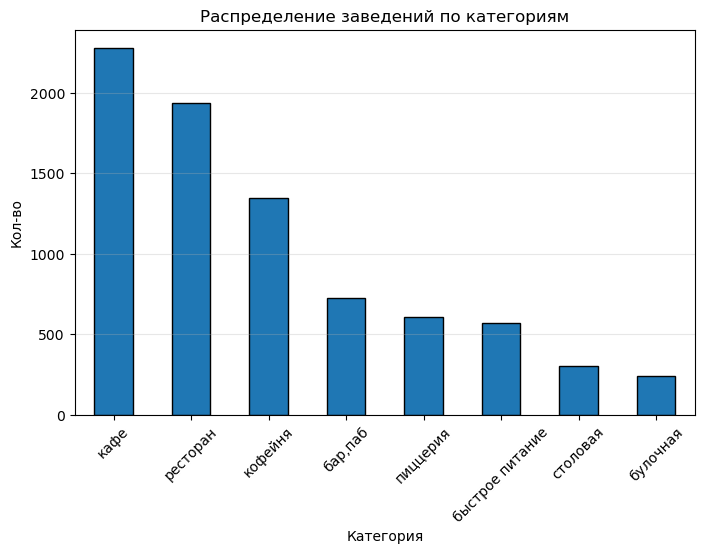

In [39]:
# Представим распределение данных по category на графике
dist_category.plot(kind='bar', edgecolor='black', figsize=(8, 5))
plt.title('Распределение заведений по категориям')
plt.xlabel('Категория')
plt.ylabel('Кол-во')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.show()

Можно сделать следующие выводы:

- **Самые популярные категории - кафе и рестораны**. Они лидируют с заметным отрывом: неудивительно, ведь это универсальные заведения.
- **Самые непопулярные категории - столовые и булочные**. Эти заведения более нишевые.

### 4.2 Анализ заведений по административным районам Москвы
Рассмотрим распределение количества заведений по административным районам Москвы, а также отдельно распределение заведений каждой категории в Центральном административном округе Москвы.

In [40]:
# Изучим распределение данных по district
dist_district = df['district'].value_counts()
dist_district

district
Центральный административный округ         2140
Северо-Восточный административный округ     861
Северный административный округ             842
Западный административный округ             821
Южный административный округ                811
Восточный административный округ            760
Юго-Западный административный округ         695
Юго-Восточный административный округ        685
Северо-Западный административный округ      392
Name: count, dtype: int64

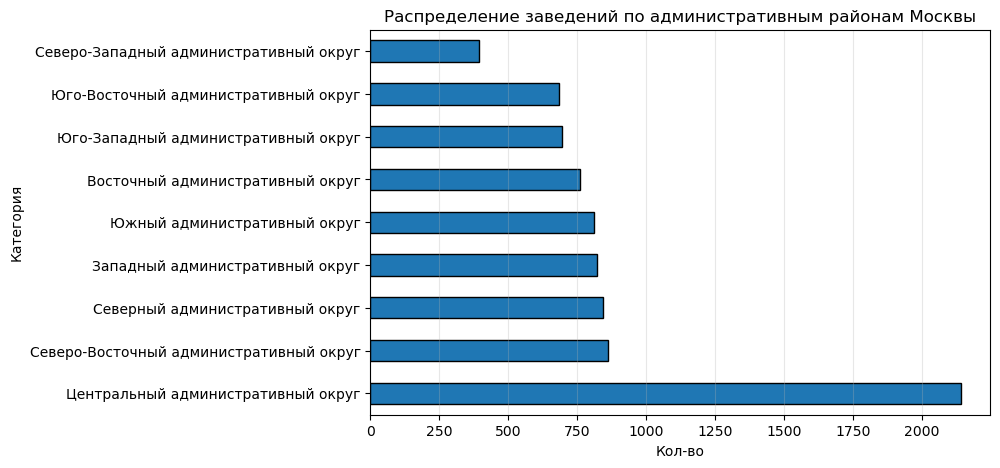

In [41]:
# Представим распределение данных по district на графике
dist_district.plot(kind='barh', edgecolor='black', figsize=(8, 5))
plt.title('Распределение заведений по административным районам Москвы')
plt.ylabel('Категория')
plt.xlabel('Кол-во')
plt.grid(axis='x', alpha=0.3)
plt.show()

Можно сделать следующие выводы:

- **Центральный административный округ лидирует с огромным отрывом.**
Львинная доля заведений располагаются именно там.
- **Северо-Западный административный округ самый малочисленный.** Этот район заметно отстает от всех оставшихся районов.

In [42]:
# Изучим распределение данных по category в Центральном районе Москвы
dist_category_c = df[df['district'] == 'Центральный административный округ']['category'].value_counts()
display(dist_category_c)

category
ресторан           630
кафе               444
кофейня            412
бар,паб            349
пиццерия           108
быстрое питание     84
столовая            64
булочная            49
Name: count, dtype: int64

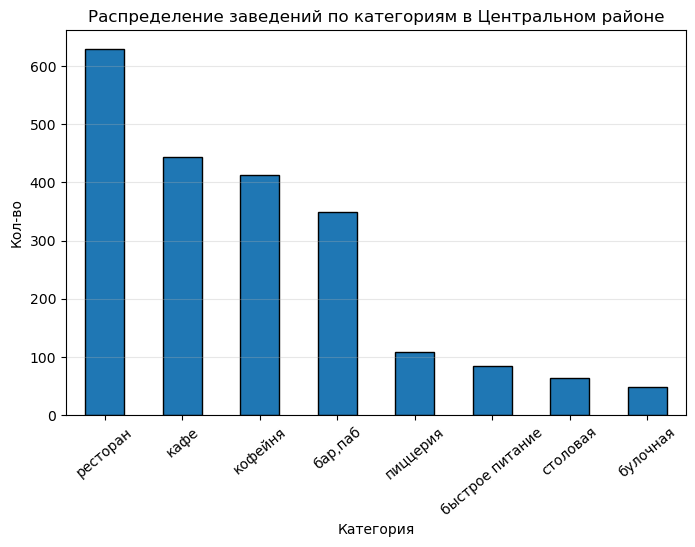

In [43]:
# Представим распределение данных в Центральном районе Москвы по district на графике
dist_category_c.plot(kind='bar', edgecolor='black', figsize=(8, 5))
plt.title('Распределение заведений по категориям в Центральном районе')
plt.xlabel('Категория')
plt.ylabel('Кол-во')
plt.xticks(rotation=40)
plt.grid(axis='y', alpha=0.3)
plt.show()

Можно сделать следующие выводы:

- **Рестораны опережают кафе.** В Центральном районе, в отличии от общей статистики, ресторанов больше, чем кафе. Вероятно это связано с большей платежеспособностью целевой аудитории, ведь в ресторанах, как правило, средний чек выше.
- **Кофейни и бары/пабы догоняют.** Также в этом районе число кофеен и баров/пабов сопоставимо с числом кафе: специализированные заведения с напитками здесь более популярны.

### 4.3 Анализ заведений по критерию (сетевое/несетевое)
Исследуем соотношение сетевых и несетевых заведений в целом по всем данным и в разрезе категорий заведения.

In [44]:
# Изучим распределение данных по критерию chain
dist_chain = df['chain'].value_counts()
dist_chain

chain
0    4965
1    3042
Name: count, dtype: int64

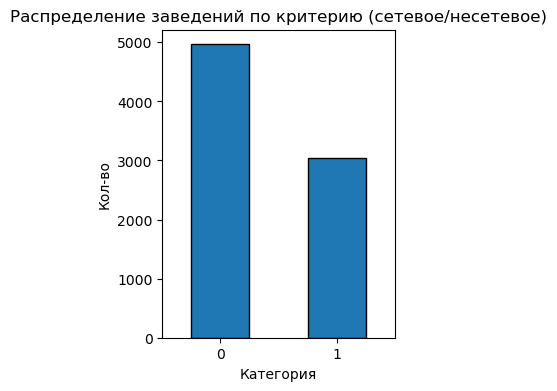

In [45]:
# Представим распределение данных по критерию chain на графике
dist_chain.plot(kind='bar', edgecolor='black', figsize=(3, 4))
plt.title('Распределение заведений по критерию (сетевое/несетевое)')
plt.xlabel('Категория')
plt.ylabel('Кол-во')
plt.xticks(rotation=0)
plt.show()

Можно сделать следующие выводы:

- **Несетевых заведений более чем в 1,5 раза больше, чем сетевых.** Пока еще крупные сети не заняли большую часть рынка.

In [46]:
# Создаем таблицу, которая группирует данные по category и chain
df_unstack = df.groupby('category', observed=True)['chain'].value_counts().unstack(fill_value=0)

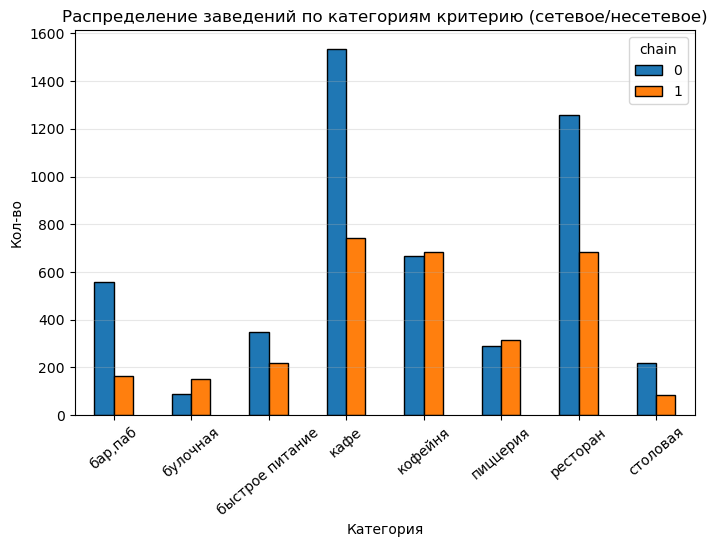

In [47]:
# Представим распределение данных по category и chain на графике
df_unstack.plot(kind='bar', edgecolor='black', figsize=(8, 5))
plt.title('Распределение заведений по категориям критерию (сетевое/несетевое)')
plt.xlabel('Категория')
plt.ylabel('Кол-во')
plt.xticks(rotation=40)
plt.grid(axis='y', alpha=0.3)
plt.show()

Можно сделать следующие выводы:

- **Доля сетевых заведений немного выше в таких категориях как:** кофейни, пиццерии, булочные.
- **Несетевые заведения доминируют в таких категориях как:** кафе, рестораны, бары/пабы, быстрое питание, столовые.

### 4.4 Анализ количества посадочных мест в заведениях
Изучим количество посадочных мест в заведениях и выявим типичное значение для каждой их категории.

In [48]:
# Изучаем статистические показатели столбца seats
print('Статистические показатели столбца seats:')
df['seats'].describe()

Статистические показатели столбца seats:


count       4399.0
mean     90.438736
std      69.667529
min            1.0
25%           40.0
50%           70.0
75%          120.0
max          300.0
Name: seats, dtype: Float64

In [49]:
# Создаем функцию для построения гистрограммы
def plot_histogram(data, bins=10, title="Гистограмма", xlabel="Значение", ylabel="Частота"):
    """
    Строит гистограмму по переданным данным.

    Параметры:
        data (list или array): числовые данные
        bins (int): количество интервалов (по умолчанию 10)
        title (str): заголовок графика
        xlabel (str): подпись оси X
        ylabel (str): подпись оси Y
    """
    plt.figure(figsize=(8, 5))
    plt.hist(data, bins=bins, edgecolor="black", alpha=0.8)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

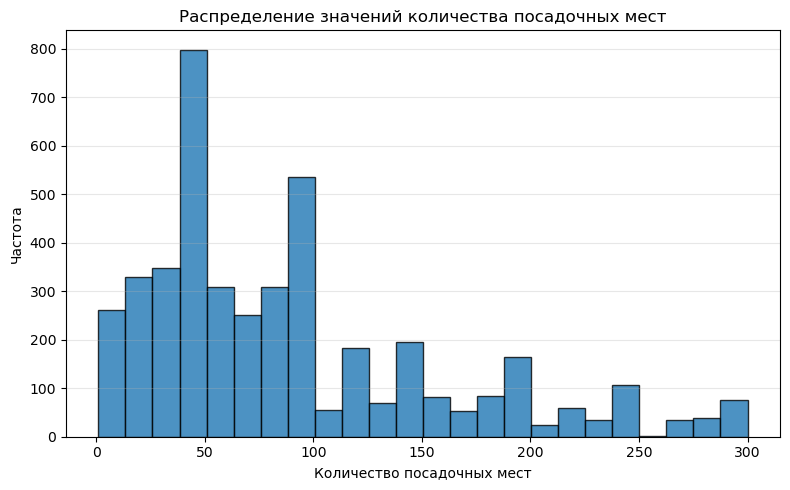

In [50]:
# Построим гистрограмму распределения значений
plot_histogram(data=df['seats'], bins=24, title='Распределение значений количества посадочных мест', xlabel='Количество посадочных мест')

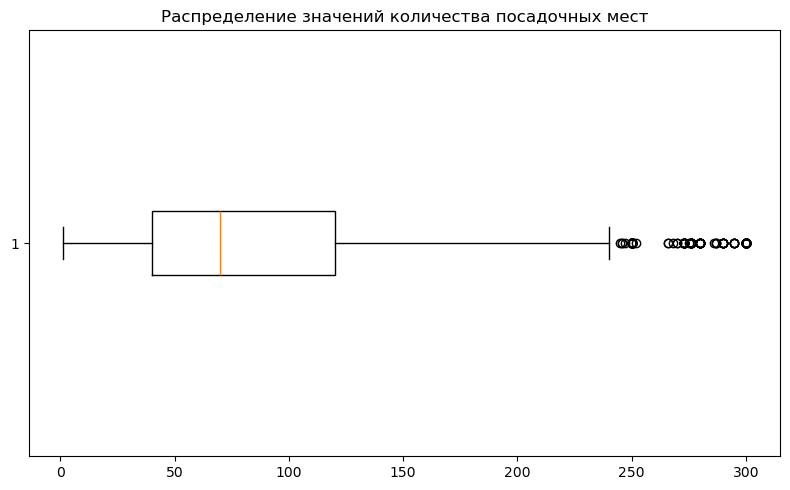

In [51]:
# Построим диаграмму размаха
plot_boxplot(data=df['seats'].dropna(), title='Распределение значений количества посадочных мест')

Можно сделать следующие выводы:

- **Типичный формат заведения небольшой на 40-50 посадочных мест.** Этому свидетельствует резкий всплеск на гистограмме. Как правило это кафе, кофейни, небольшие рестораны.
- **Также популярен более крупный сегмент на 90-100 посадочных мест.** Это подтверждается вторым, более низким, но заметным пиком. Сюда уже входят более крупные рестораны и банкетные залы.
- **Есть резкий спад после 100 посадочных мест.** Заведения, чаще всего, стараются не превышать это значение.
- **Распределение сильно скошено вправо.** Это видно по статистике (среднее 90.4 существенно выше медианы 70.0), по гистограмме (хвост от 100 до 300) и по ящику с усами (усы и выбросы вытянуты в сторону больших значений). Данное явление говорит о том, что есть немало заведений, которые выбиваются из привычной картины и делают ставку на масштаб.

Теперь найдем типичное значение для каждой категории заведений. Из-за сильного влияния выбросов оптимальнее будет использовать для этого медиану.

In [52]:
# Считаем медиану посадочных мест по каждой категории
seats_by_category = df.groupby('category', observed=True)['seats'].median().sort_values(ascending=False)

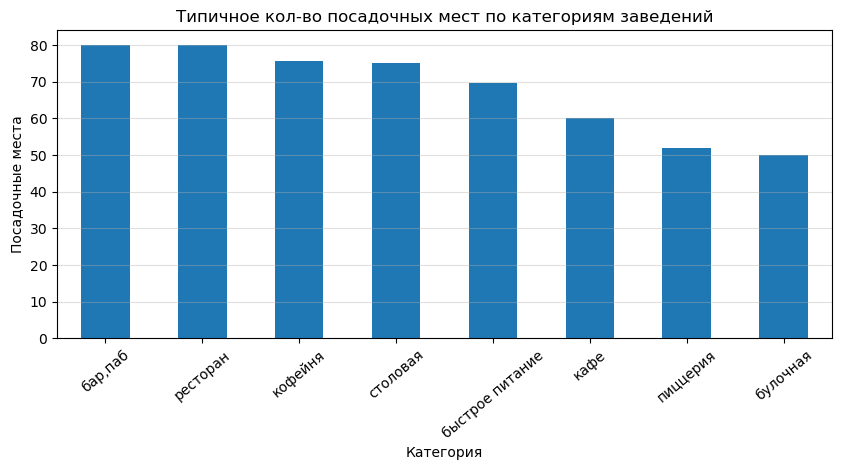

In [53]:
# Представим типичное кол-во посадочных мест по category
seats_by_category.plot(kind='bar', figsize=(10, 4))
plt.title('Типичное кол-во посадочных мест по категориям заведений')
plt.ylabel('Посадочные места')
plt.xlabel('Категория')
plt.grid(axis='y', alpha=0.4)
plt.xticks(rotation=40)
plt.show()

Можно сделать следующие выводы:

- **Лидеры - бары/пабы и рестораны.** В этих категориях заведений в среднем около 80 посадочных мест.
- **Аутсайдеры - пиццерии и булочные.** Там в среднем около 50 посадочных мест.

### 4.5 Анализ рейтинга заведений
Исследуем рейтинг заведений и визуализируем распределение средних рейтингов по категориям заведений.

In [54]:
# Изучаем статистические показатели столбца rating
print('Статистические показатели столбца rating:')
df['rating'].describe()

Статистические показатели столбца rating:


count    8007.000000
mean        4.230523
std         0.471180
min         1.000000
25%         4.100000
50%         4.300000
75%         4.400000
max         5.000000
Name: rating, dtype: float64

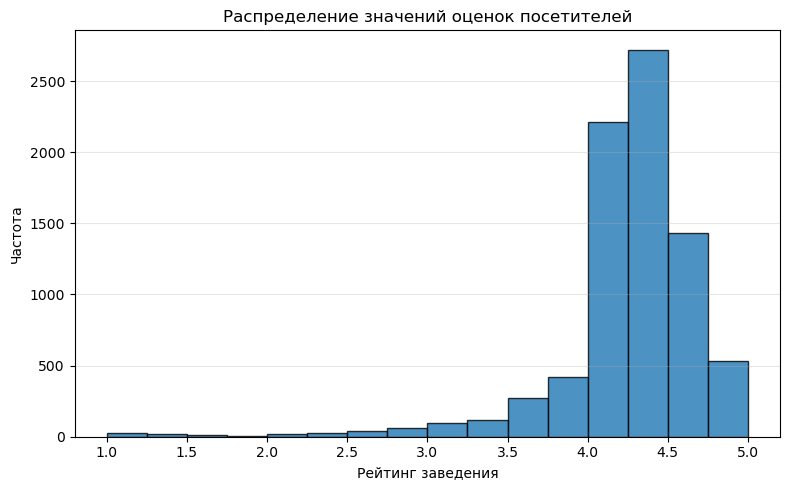

In [55]:
# Построим гистрограмму распределения значений
plot_histogram(data=df['rating'], bins=16, title='Распределение значений оценок посетителей', xlabel='Рейтинг заведения')

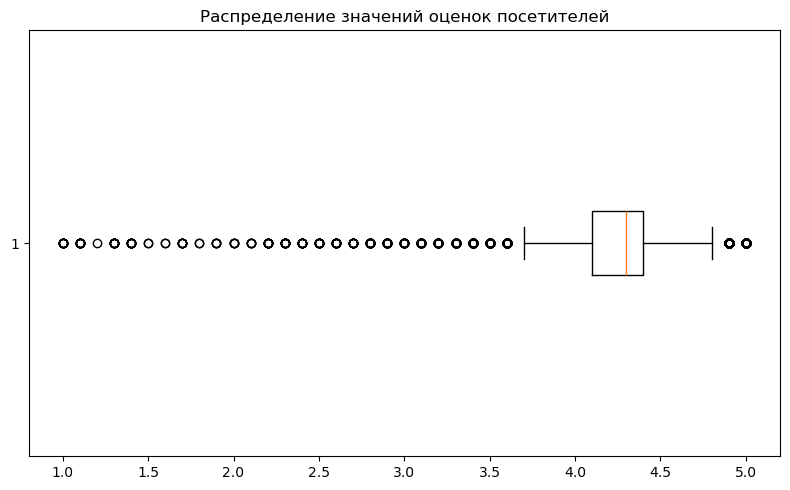

In [56]:
# Построим диаграмму размаха
plot_boxplot(data=rest_df['rating'], title='Распределение значений оценок посетителей')

Можно сделать следующие выводы:

- **На гистограмме заметен ярко выраженный пик в районе 4.25–4.5.** Это мода распределения: именно такие оценки ставят чаще всего.
- **На гистограмме и графике ящика с усами слева виден длинный хвост и большое количество выбросов в диапазоне 1.0–3.5.** Это реальные заведения с низкими рейтингами, которые статистически отличаются от основной массы.
- **Стандартное отклонение низкое (0.47) и более половины всех посетителей ставят оценку в диапазоне от 4.0 до 4.5.** Это говорит о низком разбросе данных и поляризации оценок в хорошую сторону - следовательно, либо поведение большинства посетителей схоже в вопросе выставления оценок, либо заведения стабильно хорошие.
- **Между оценками выше 4.0 и ниже есть заметный разрыв.** Возможно заведения с рейтингом ниже 4.0 быстро исправляют эту ситуацию или в итоге уходят с рынка.

In [57]:
# Считаем медиану рейтинга по каждой категории заведений
rating_by_category = df.groupby('category', observed=True)['rating'].median().sort_values(ascending=False)

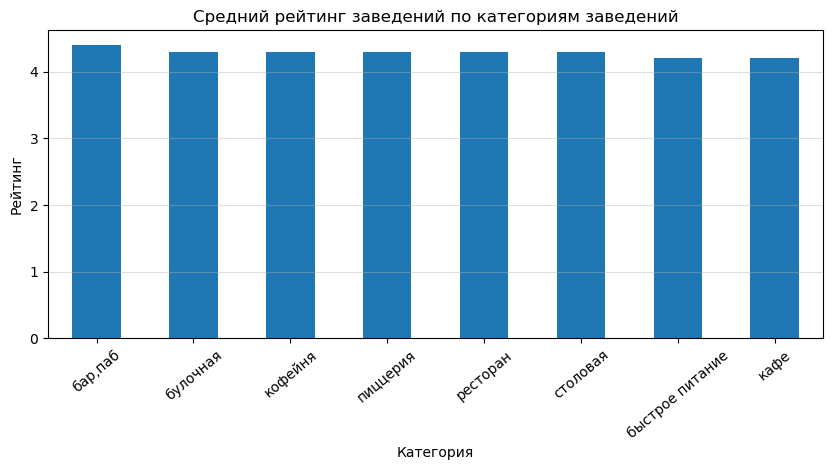

In [58]:
# Представим средний рейтинг заведений по каждой категории заведений на графике
rating_by_category.plot(kind='bar', figsize=(10, 4))
plt.title('Средний рейтинг заведений по категориям заведений')
plt.ylabel('Рейтинг')
plt.xlabel('Категория')
plt.grid(axis='y', alpha=0.4)
plt.xticks(rotation=40)
plt.show()

Можно сделать следующие выводы:

- **Усредненные рейтинги практически не различаются между разными категориями заведений**

### 4.6 Анализ корреляции рейтинга заведения с другими данными
Рассмотрим, с какими данными рейтинги заведений показывают самую сильную корреляцию.

In [59]:
# Отберем данные для матрицы корреляции
cols_for_phik = ['rating', 'category', 'district', 'chain', 'seats', 'price', 'is_24_7']
df_phik = df[cols_for_phik]

In [60]:
# Посчитаем матрицу корреляций
phik_matrix = df_phik.phik_matrix()

interval columns not set, guessing: ['rating', 'chain', 'seats']


In [61]:
# Оставляем только корреляции с rating
rating_corr = phik_matrix['rating']
rating_corr = rating_corr.drop('rating')

In [62]:
# Отсортирум значения
rating_corr = rating_corr.sort_values(ascending=False)

In [63]:
# Превратим объект Series в одностолбцовый DataFrame
rating_corr_df = rating_corr.to_frame(name='rating PhiK')

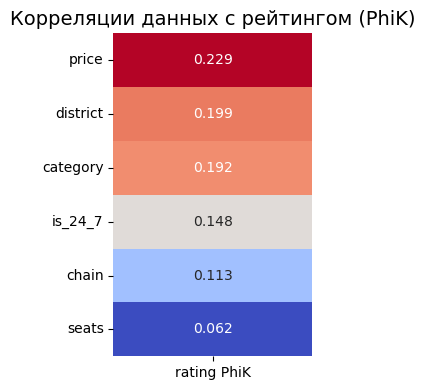

In [64]:
# Визуализируем получившуюся матрицу корреляции с помощью тепловой карты
plt.figure(figsize=(3, 4))
sns.heatmap(
    rating_corr_df,
    annot=True,
    fmt=".3f",
    cmap='coolwarm',
    cbar=False
)
plt.title('Корреляции данных с рейтингом (PhiK)', fontsize=14)
plt.tight_layout()
plt.yticks(rotation=0, va='center') 
plt.show()

Можно сделать следующие выводы:

- **Со всеми показателями, кроме seats, значение PhiK лежит в диапазоне 0.1-0.3.** Это говорит о наличии слабой связи.
- **Наиболее сильная, относительно прочих, зависимость рейтинга наблюдается от ценовой категории заведения.** Проверим отдельно эту связь.

In [65]:
# Изучим сводную статистику по ценовым категориям
df.groupby('price', observed=True)['rating'].agg(['mean', 'median', 'std', 'count']).round(3)

,mean,median,std,count
price,,,,
высокие,4.437,4.4,0.321,441
выше среднего,4.391,4.4,0.225,539
низкие,4.167,4.2,0.375,148
средние,4.298,4.3,0.290,2032


Действительно, чем выше ценовая категория заведения, тем выше средний рейтинг и его медианное значение.

### 4.7 Анализ самых популярных сетей заведений
Найдем топ-15 популярных сетей в Москве, определим их категорию и посчитаем для них значения среднего рейтинга. Под популярностью понимается количество заведений этой сети в регионе. 

In [66]:
# Создадим сводную таблицу: популярность (count) и средний рейтинг (mean)
pivot = pd.pivot_table(
    df,
    values='rating',
    index=['name', 'category'],
    aggfunc={'rating': ['count', 'mean']},
    observed=False
)

# Сортируем по популярности и берем топ-15
top_15_pivot = pivot.sort_values('count', ascending=False).head(15)

# Выводим результат
top_15_pivot

,,count,mean
name,category,,
кафе,кафе,156,3.843590
шоколадница,кофейня,113,4.176991
домино'с пицца,пиццерия,76,4.171053
додо пицца,пиццерия,71,4.281690
one price coffee,кофейня,67,4.077612
яндекс лавка,ресторан,63,3.850794
cofix,кофейня,62,4.072581
prime,ресторан,46,4.110870
кофепорт,кофейня,40,4.152500


Можно сделать следующие выводы:

- **Чаще всего встречаются заведения с названием "кафе".** Это не сеть, а типовое название для подобных заведений. Учитывая, что кафе это самая популярная категория заведений в Москве, такой результат не удивителен.
- **Самое популярное сетевое заведение - "Шоколадница".** Это заведение относится к типу кофейня, имеет 113 точек и средний рейтинг 4.18.
- **Следом идут "Домино'с пицца" и "Додо пицца".** Эти сети уже являются, как ни странно, пиццериями, имеют 76 и 71 точек, средний рейтинг 4.17 и 4.28 соответственно.
- **Наиболее высокие средние оценки у сетей "Буханка" и "Кулинарная лавка братьев караваевых".** Их средние оценки - 4.42 и 4.40 соответственно.

### 4.8 Анализ среднего чека по районам
Изучим вариацию среднего чека заведения (столбец `middle_avg_bill`) в зависимости от района Москвы. Проанализируем, как удалённость от центра влияет на цены в заведениях.

In [67]:
# Изучаем статистические показатели столбца middle_avg_bill
print('Статистические показатели столбца middle_avg_bill:')
df['middle_avg_bill'].describe()

Статистические показатели столбца middle_avg_bill:


count    2990.000000
mean      926.638796
std       725.404874
min        30.000000
25%       375.000000
50%       700.000000
75%      1250.000000
max      5000.000000
Name: middle_avg_bill, dtype: float64

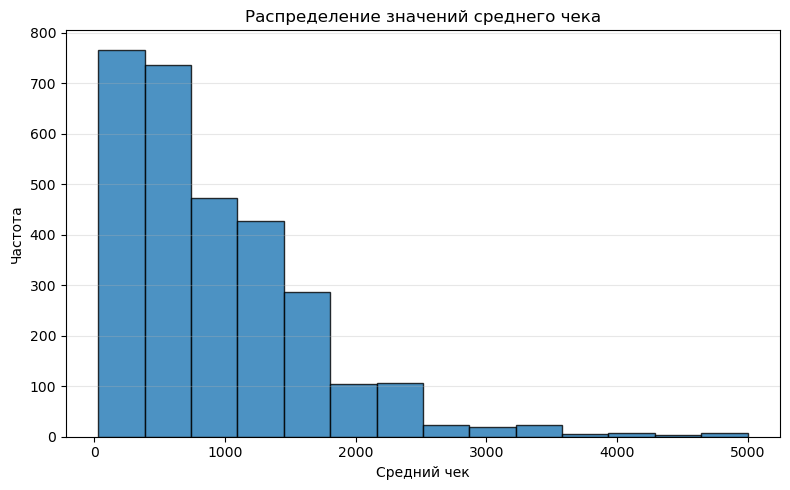

In [68]:
# Построим гистрограмму распределения значений
plot_histogram(data=df['middle_avg_bill'], bins=14, title='Распределение значений среднего чека', xlabel='Средний чек')

In [69]:
# Считаем медиану среднего чека по каждому району
rating_by_category = df.groupby('district', observed=True)['middle_avg_bill'].median().sort_values(ascending=False)

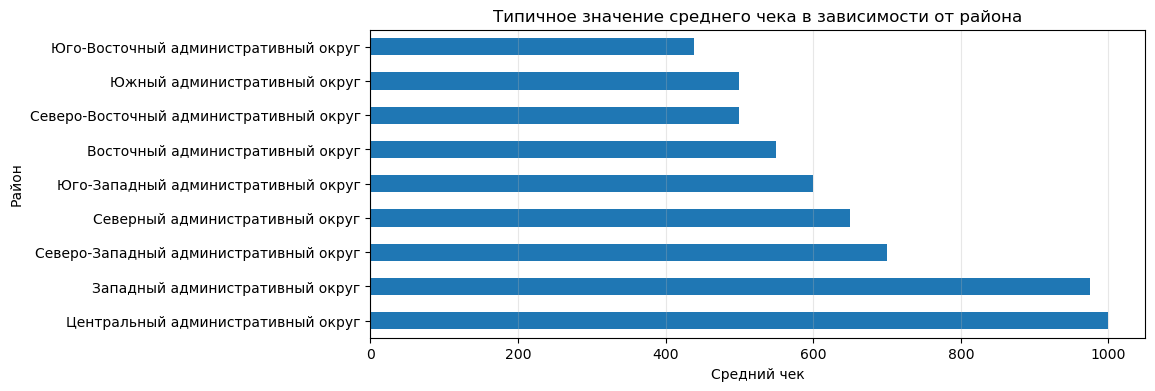

In [70]:
# Представим медианное значение среднего чека заведений по районам на графике
rating_by_category.plot(kind='barh', figsize=(10, 4))
plt.title('Типичное значение среднего чека в зависимости от района')
plt.xlabel('Средний чек')
plt.ylabel('Район')
plt.grid(axis='x', alpha=0.3)
plt.xticks(rotation=0)
plt.show()

Можно сделать следующие выводы:

- **Самый высокий средний чек в Центральном и Западном районах.** Там это значение находится в районе 950-1000 ₽.
- **Самый низкий средний чек в Юго-Восточном районе.** Это примерно 400-450 ₽.
- **Медианное значение в целом по Москве равно 700 ₽.** В большинстве районов средний чек ниже этого значения.
- **Чем дальше от центра, тем ниже средний чек.** Средний чек уменьшается в следующем порядке Центр -> Запад -> Север -> Восток -> Юг.

## 5. Итоговые выводы и рекомендации

### 5.1 Обзор проделанной работы
- В ходе исследования были проанализированы данные 8406 заведений общественного питания в городе Москва.
- Они включали информацию как о самом заведении, так и об уровне цен в нем.
- Был осуществлен предварительный обзор данных и их предобработка.
- Ацент исследования был поставлен на том, чтобы сформировать общее представление о ситуации на рынке общественного питания в Москве, выявить закономерности в данных и взаимосвязи между различными показателями.
- На поставленные вопросы были получены ответы, которые будут прорезюмированы в следующем пункте.

### 5.2 Общие выводы
Далее будут изложены ответы на поставленные в начале работы вопросы, а также дополнительные инсайты.
<br>
<br>

1. **Какие категории заведений представлены в данных? Сколько заведений каждой категории?**

Больше всего в Москве кафе, далее идут рестораны, а наиболее редкие типы заведений - столовые и булочные.
<br>
<br>

2. **Как заведения распределяются по административным районам Москвы? Есть ли разница в распределении по категориям в Центральном районе?**

В ЦАО сосредоточено 2140 заведений - более чем в 2 раза больше, чем в любом другом районе. При этом рестораны в этом районе встречаются чаще, чем кафе.
<br>
<br>

3. **Каких заведений больше — сетевых или несетевых? Какие категории заведений чаще являются сетевыми?**

Несетевых заведений в Москве более чем в 1,5 раза больше, чем сетевых. Доля сетевых заведений больше всего среди кофеен, пиццерий и булочных.
<br>
<br>

4. **Встречаются ли в данных о количестве посадочных мест аномальные значения или выбросы? Если да, то с чем они могут быть связаны? Какое типичное количество мест для разных категорий заведений?**

Выбросы в этих данных есть и расположены они в правой части - это крупные значения вплоть до 1200+ мест. Это могут быть крупные банкетные залы, фудкорты, которые делают ставку на крупные мероприятия. Типичные значения по категориям: бары и рестораны - 80, кофейни и столовые - 75, быстрое питание - 70, кафе - 60, пиццерии и булочные - 50. При этом среди всех заведений есть два отличительных пика по посадочным местам - это 40-50 посадочных мест (небольшие заведения) и 90-100 (крупные заведения).
<br>
<br>

5. **Какие типичные типичные значения рейтинга в целом и у различных категорий заведений?**

Более половины всех посетителей ставят оценку в диапазоне от 4.0 до 4.5, медианное значение 4.3 и оно практически не отличается среди различных типов заведений. При этом ниже оценки 4.0 заведений становится резко меньше, что может свидетельствовать о важности поддержания оценки выше этого уровня.
<br>
<br>

6. **С какими данными рейтинги заведений показывают самую сильную корреляцию?**

Наиболее сильная корреляция рейтинга наблюдается с ценовым сегментом заведения - чем выше ценовой сегмент, тем в среднем выше рейтинг. Но уровень данной статистической связи является достаточно низким: это означает, что показатели имеют некоторую общую закономерность, но один признак плохо предсказывается по другому.
<br>
<br>

7. **Какие сетевые заведения имеют больше всего точек? К какой категории заведений они относятся?**

Самая популярная сеть - кофейни "Шоколадница" (113 точек, средний рейтинг 4.18). Далее следуют пиццерии "Домино'с пицца" (76 точек, рейтинг 4.17) и "Додо пицца" (71 точчка, рейтинг 4.28). При этом наибольший средний рейтинг среди топ-15 заведений по числу точек у сети булочных "Буханка" (25 точек, рейтинг 4.42).
<br>
<br>

8. **Как удаленность от центра влияет на цены в заведениях?**

Самый высокий средний чек в Центральном и Западном районах (950-1000 ₽), это на 250-300 ₽ выше медианного значения по Москве. В большинстве районнов средний чек ниже медианного значения. Можно утверждать, что средний чек уменьшается в следующем порядке Центр -> Запад -> Север -> Восток -> Юг.

### 5.3 Рекомендации

По итогам анализа были составлены следующие рекомендации:

- **Рассмотреть Центральный административный округ как приоритетную локацию.**
Здесь больше всего заведений и при этом именно здесь рестораны по количеству опережают кафе, а кофейни и бары также представлены в большом количестве. Это говорит о высокой концентрации спроса и развитой ресторанной инфраструктуре. Однако высокая конкуренция в центре является существенным риском, поэтому при выборе конкретного места необходимо дополнительно оценить окружение, трафик и наличие прямых конкурентов.

- **В качестве альтернативы рассмотреть Западный административный округ.**
Западный округ сочетает относительно высокие цены и меньшее количество заведений, чем ЦАО. Средний чек здесь находится примерно на том же уровне. Поэтому Западный округ может быть интересен как компромисс между платежеспособностью аудитории и конкуренцией в центре.

- **Не выбирать формат только на основании популярности категории.**
Кафе и рестораны являются наиболее распространёнными категориями: 2278 и 1938 заведений соответственно. Поэтому открытие еще одного типового кафе или ресторана без четкой концепции может привести к проблемам с высокой конкуренцией. Важно сделать ставку на отличимую концепцию, которая позволит выделиться среди большого количества существующих заведений.

- **Предпочтительно выбрать несетевой формат.**
Несетевых заведений в Москве больше сетевых, а значит, рынок не поглощен крупными сетями. При этом сетевой формат особенно распространен среди кофеен, пиццерий и булочных. Для инвесторов это создаёт возможность построить самостоятельный бренд с уникальной концепцией, меню и позиционированием.

- **Ориентироваться примерно на 50–80 посадочных мест в зависимости от типа заведения.**
Типичное заведение на рынке — относительно небольшое. В исследовании наиболее заметны форматы на 40–50 и 90–100 мест: разумнее ориентироваться на первый формат, чтобы не брать на себя избыточные затраты крупного помещения и при этом обеспечить достаточную вместимость. Для такого формата подойдут пиццерия или булочная. Если же открывать кафе или ресторан, то придется обеспечить большее количество мест, чтобы соответствовать рынку.

- **Установить средний чек около 700–1000 ₽.**
Для ЦАО/ЗАО можно рассматривать позиционирование в среднем или выше среднего ценовом сегменте. При этом заведения более высокого ценового сегмента чаще имеют более высокие рейтинги, но не стоит чрезмерно завышать цены: исследование показывает, что хоть связь между ценовым сегментом и рейтингом существует - она слабая.

- **Особое внимание уделить качеству сервиса и поддержанию рейтинга не ниже 4,0.**
Медианный рейтинг заведений составляет 4,3, а более половины заведений имеют оценку в диапазоне 4,0–4,5. При рейтинге ниже 4,0 количество заведений резко сокращается. Поэтому после открытия необходимо регулярно отслеживать отзывы и оперативно устранять причины негативных оценок.

- **Следующим этапом стоит провести более детальный анализ конкретных локаций.** Необходимо изучить: количество конкурентов в радиусе, их рейтинги и цены, транспортную доступность и потенциальный клиентский поток. Это позволит выбрать конкретную точку с хорошим соотношением спроса и конкуренции.